# Aerial Image Segmentation: Fuzzy C-Means vs K-Means

**Question.** Each pixel of a 200 x 200 aerial photograph is grouped by colour into land-cover classes (vegetation, bare ground, built surfaces). K-Means gives every pixel exactly one class. Fuzzy C-Means (FCM) gives every pixel a *degree of membership* in each class. What does that extra information add?

**Approach**
1. Pixels as points in RGB space
2. Choose the number of clusters: K-Means inertia and silhouette, FCM partition coefficient
3. Segment with both methods and measure agreement
4. Use FCM memberships to map uncertain (mixed) pixels
5. Study the effect of the fuzzifier *m*

## How Fuzzy C-Means works
FCM minimises $J_m = \sum_i \sum_j u_{ij}^m \lVert x_i - c_j \rVert^2$, where $u_{ij} \in [0, 1]$ is pixel *i*'s membership in cluster *j*, and the memberships of each pixel sum to 1. It alternates between two updates:
- Centroids are membership-weighted means: $c_j = \sum_i u_{ij}^m x_i / \sum_i u_{ij}^m$
- Memberships depend on relative distance: $u_{ij} = 1 / \sum_k (d_{ij} / d_{ik})^{2/(m-1)}$

The **fuzzifier** $m > 1$ controls softness. As $m \to 1$, FCM becomes K-Means; larger *m* spreads membership more evenly. The **fuzzy partition coefficient** $FPC = \frac{1}{N}\sum_i\sum_j u_{ij}^2$ ranges from $1/c$ (completely fuzzy) to 1 (crisp).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os; os.environ['LOKY_MAX_CPU_COUNT'] = '1'
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from skfuzzy.cluster import cmeans
RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110})
pd.options.display.float_format = '{:,.3f}'.format

Image 200 x 200 -> 40,000 pixels x 3 channels | distinct colours: 24,846


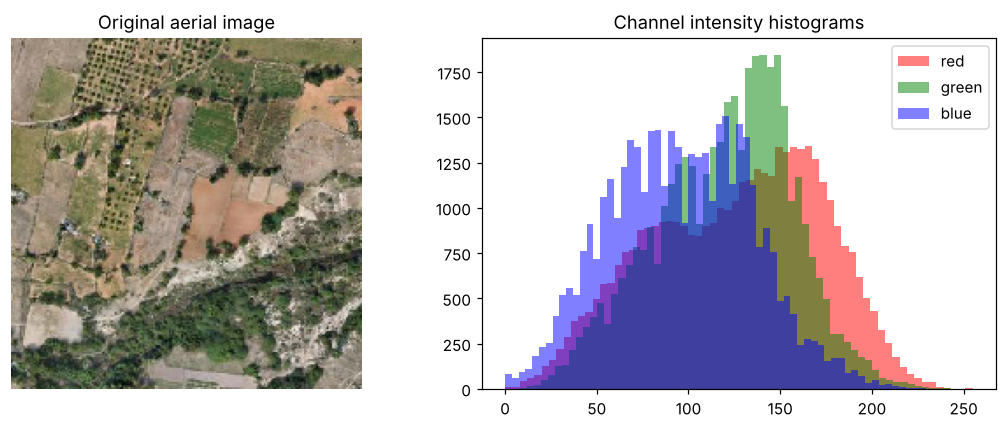

In [2]:
img = np.array(Image.open('../data/aerial_img.png').convert('RGB'))
H, W, _ = img.shape
pixels = img.reshape(-1, 3).astype(float)
print(f'Image {H} x {W} -> {len(pixels):,} pixels x 3 channels | distinct colours: {len(np.unique(img.reshape(-1, 3), axis=0)):,}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img); axes[0].axis('off'); axes[0].set_title('Original aerial image')
for ch, col in zip(range(3), ['red', 'green', 'blue']):
    axes[1].hist(img[..., ch].ravel(), bins=64, color=col, alpha=0.5, label=col)
axes[1].set_title('Channel intensity histograms'); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'original_and_histograms.png', bbox_inches='tight'); plt.show()

**Observation:** A 200 x 200 aerial image (40,000 pixels) of farmland, orchards, scrub and a wooded gully, containing 24,846 distinct colours. All three channel histograms are broad and overlapping. Colour classes will blend into one another rather than separate sharply, which is the setting where soft clustering should help.

## 1. How Many Clusters?

,k,K-Means inertia,Silhouette (K-Means),FCM partition coefficient,Inertia drop from k-1 (%)
0,2,"65,029,624.631",0.573,0.832,NaN
1,3,"36,222,454.592",0.488,0.745,44.299
2,4,"24,851,493.761",0.442,0.684,31.392
3,5,"17,877,117.089",0.439,0.657,28.064
4,6,"14,288,344.720",0.406,0.617,20.075
5,7,"12,027,103.339",0.386,0.585,15.826
6,8,"10,510,044.345",0.358,0.555,12.614


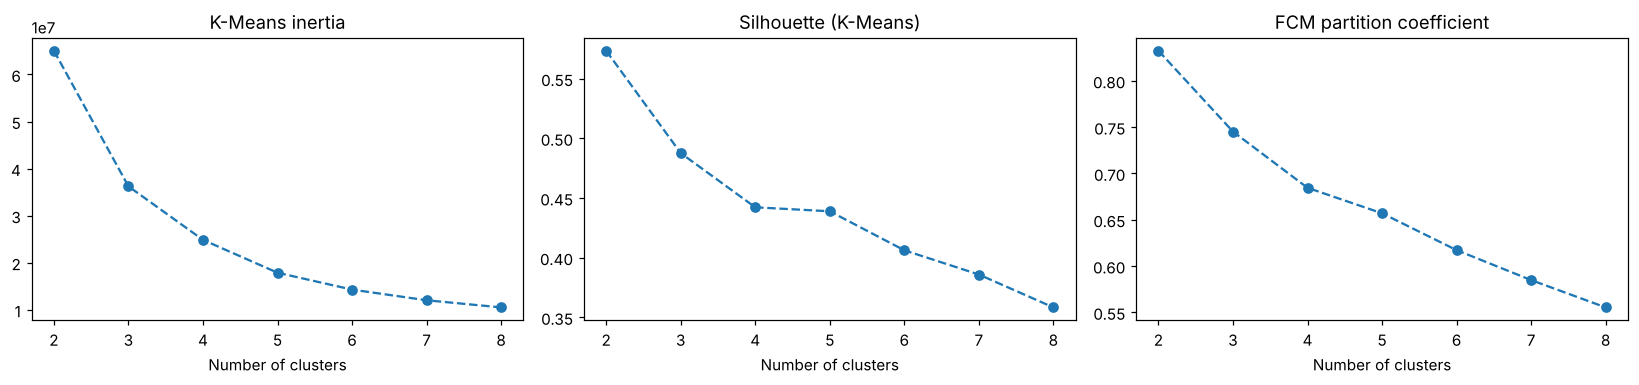

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
sample = rng.choice(len(pixels), 5000, replace=False)        # silhouette on a sample keeps this fast
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(pixels)
    _, u, _, _, _, _, fpc = cmeans(pixels.T, c=k, m=2, error=0.005, maxiter=1000, seed=RANDOM_STATE)
    rows.append({'k': k, 'K-Means inertia': km.inertia_, 'Silhouette (K-Means)': silhouette_score(pixels[sample], km.labels_[sample]),
                 'FCM partition coefficient': fpc})
k_tbl = pd.DataFrame(rows); k_tbl['Inertia drop from k-1 (%)'] = -100 * k_tbl['K-Means inertia'].pct_change()
display(k_tbl.round(3)); k_tbl.round(4).to_csv(MET_DIR / 'k_selection.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ['K-Means inertia', 'Silhouette (K-Means)', 'FCM partition coefficient']):
    ax.plot(k_tbl['k'], k_tbl[col], 'o--'); ax.set_title(col); ax.set_xlabel('Number of clusters')
plt.tight_layout(); plt.savefig(FIG_DIR / 'k_selection.png', bbox_inches='tight'); plt.show()

**Observation:** The criteria disagree, as they often do on image data. The silhouette score and the FCM partition coefficient both fall steadily from k = 2 (0.573 and 0.832), because more clusters always make the partition less crisp. Inertia drops 44% from k = 2 to 3 and 31% from 3 to 4, then the curve flattens. k = 3 is the main segmentation (dark tree cover, mid-tone fields, bright bare ground), with k = 5 shown for finer detail.

## 2. Segmentation with Both Methods
Each segment is painted with its centroid colour, so the result reads like a simplified version of the photograph.

k = 3: hard-label agreement K-Means vs FCM = 0.9925 (299 pixels differ) | FPC = 0.745


k = 5: hard-label agreement K-Means vs FCM = 0.9771 (916 pixels differ) | FPC = 0.657


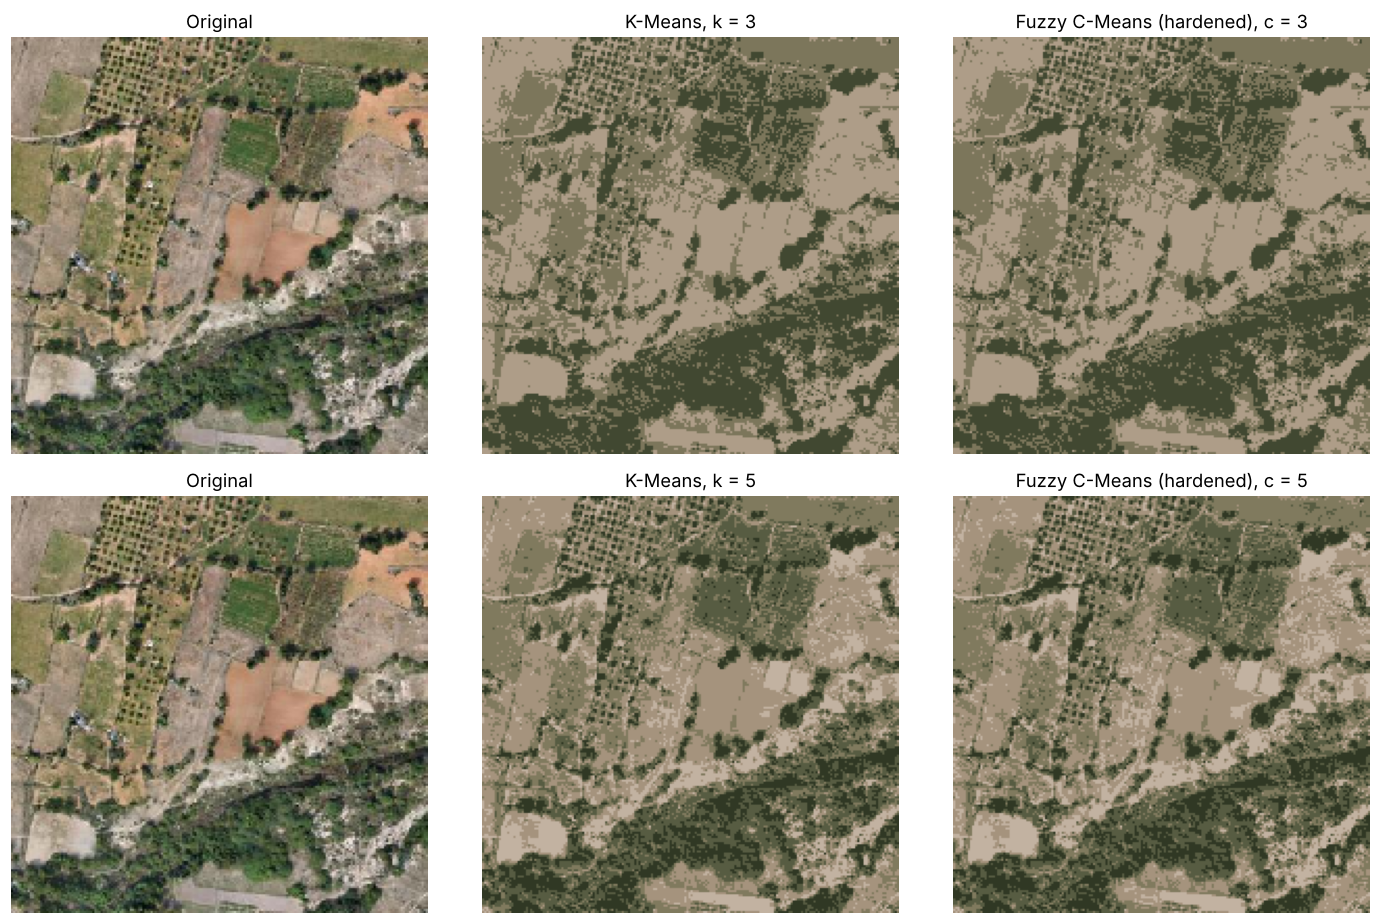

In [4]:
def match_labels(ref, other, k):
    """Relabel `other` to best agree with `ref` (Hungarian matching on the contingency table)."""
    cont = pd.crosstab(ref, other).reindex(index=range(k), columns=range(k), fill_value=0).values
    r, c = linear_sum_assignment(-cont)
    mapping = dict(zip(c, r)); return np.vectorize(mapping.get)(other)

seg = {}
for k in [3, 5]:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(pixels)
    cntr, u, _, _, _, _, fpc = cmeans(pixels.T, c=k, m=2, error=0.005, maxiter=1000, seed=RANDOM_STATE)
    fcm_lab = match_labels(km.labels_, u.argmax(axis=0), k)
    seg[k] = {'km': km, 'u': u, 'cntr': cntr, 'fcm_lab': fcm_lab, 'fpc': fpc,
              'agree': (fcm_lab == km.labels_).mean()}
    print(f'k = {k}: hard-label agreement K-Means vs FCM = {seg[k]["agree"]:.4f} '
          f'({int((1 - seg[k]["agree"]) * len(pixels)):,} pixels differ) | FPC = {fpc:.3f}')

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for row, k in enumerate([3, 5]):
    km = seg[k]['km']; cent = km.cluster_centers_.astype(np.uint8)
    axes[row, 0].imshow(img); axes[row, 0].set_title('Original')
    axes[row, 1].imshow(cent[km.labels_].reshape(H, W, 3)); axes[row, 1].set_title(f'K-Means, k = {k}')
    axes[row, 2].imshow(cent[seg[k]['fcm_lab']].reshape(H, W, 3)); axes[row, 2].set_title(f'Fuzzy C-Means (hardened), c = {k}')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / 'segmentation_kmeans_vs_fcm.png', bbox_inches='tight'); plt.show()

**Observation:** Once FCM memberships are hardened to the strongest class, the two methods are almost identical: 99.25% of pixels get the same label at k = 3 (299 differ) and 97.7% at k = 5 (916 differ). On hard labels alone, FCM adds little over K-Means here. Its value lies in the memberships.

In [5]:
k = 3
cent = pd.DataFrame(seg[k]['km'].cluster_centers_.round(0), columns=['R', 'G', 'B'])
cent.index.name = 'K-Means cluster'
cent['Pixel share'] = np.bincount(seg[k]['km'].labels_) / len(pixels)
cent['Brightness'] = cent[['R', 'G', 'B']].mean(axis=1).round(0)
cent['Green excess (G - (R+B)/2)'] = (cent['G'] - (cent['R'] + cent['B']) / 2).round(1)
display(cent.sort_values('Brightness'))
cent.to_csv(MET_DIR / 'centroids_k3.csv', index=False)

,R,G,B,Pixel share,Brightness,Green excess (G - (R+B)/2)
K-Means cluster,,,,,,
0,66.000,73.000,50.000,0.279,63.000,15.000
2,124.000,119.000,91.000,0.363,111.000,11.500
1,175.000,157.000,137.000,0.358,156.000,1.000


**Observation:** At k = 3 the centroids form a brightness ladder. The dark green cluster (28% of pixels) is tree cover and shadow; the mid-tone olive cluster (36%) is cultivated fields and scrub; the bright beige cluster (36%) is bare soil, dry riverbed and paths. Green excess falls from 15 to about 1 as brightness rises.

## 3. What Fuzzy Memberships Add: an Uncertainty Map
For each pixel, *max membership* is the confidence in its assigned class. Pixels with max membership below 0.6 are treated as **ambiguous**: they sit between colour classes and typically mark edges, shadows or mixed land cover.

Ambiguous pixels (max membership < 0.6) at c = 3, m = 2: 10.9%


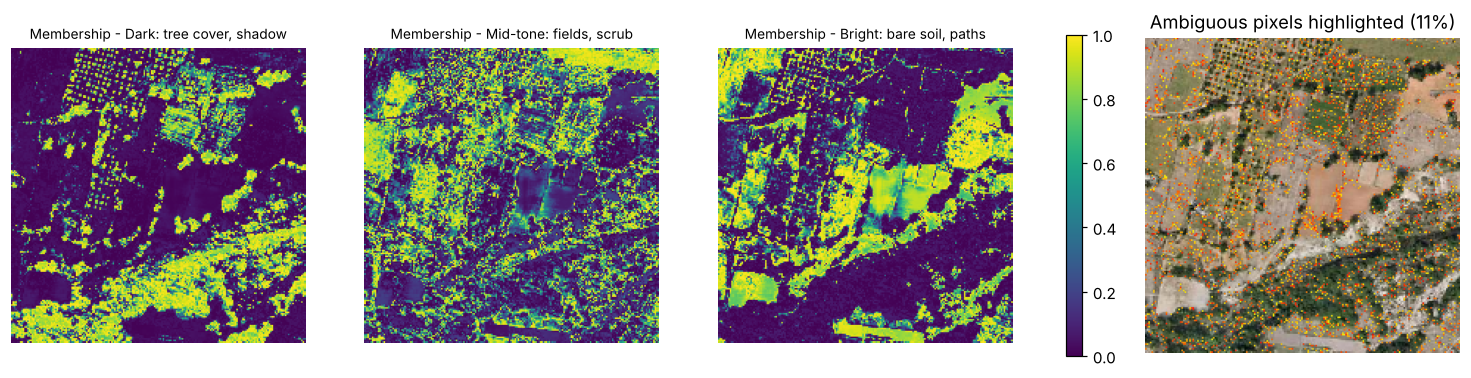

Mean max-membership where K-Means and FCM disagree: 0.489 vs where they agree: 0.832


In [6]:
k = 3; u = seg[k]['u']
maxu = u.max(axis=0).reshape(H, W)
amb_share = (maxu < 0.6).mean()
print(f'Ambiguous pixels (max membership < 0.6) at c = 3, m = 2: {amb_share:.1%}')
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
order = np.argsort(seg[k]['cntr'].mean(axis=1))          # FCM clusters from darkest to brightest centroid
names = ['Dark: tree cover, shadow', 'Mid-tone: fields, scrub', 'Bright: bare soil, paths']
for pos, j in enumerate(order):
    im = axes[pos].imshow(u[j].reshape(H, W), cmap='viridis', vmin=0, vmax=1); axes[pos].set_title(f'Membership - {names[pos]}', fontsize=9)
axes[3].imshow(img); axes[3].imshow(np.ma.masked_where(maxu >= 0.6, maxu), cmap='autumn', alpha=0.9)
axes[3].set_title(f'Ambiguous pixels highlighted ({amb_share:.0%})')
for ax in axes: ax.axis('off')
fig.colorbar(im, ax=axes[:3], fraction=0.015)
plt.savefig(FIG_DIR / 'fcm_membership_and_uncertainty.png', bbox_inches='tight'); plt.show()
diff_mask = (seg[k]['fcm_lab'] != seg[k]['km'].labels_)
print(f'Mean max-membership where K-Means and FCM disagree: {u.max(axis=0)[diff_mask].mean():.3f} '
      f'vs where they agree: {u.max(axis=0)[~diff_mask].mean():.3f}')

**Observation:** 10.9% of pixels have no dominant class (maximum membership below 0.6). They concentrate along field edges, orchard rows and the transition between scrub and bare ground. The pixels where K-Means and FCM disagree are exactly these: their average maximum membership is 0.49, against 0.83 where the methods agree. FCM flags the pixels a hard classifier is most likely to get wrong, which is useful for deciding where manual review or higher-resolution imagery is needed.

## 4. Effect of the Fuzzifier m

,m,FPC,Ambiguous pixels (max u < 0.6),Agreement with K-Means,Iterations
0,1.250,0.951,0.020,0.995,43
1,1.500,0.893,0.043,0.994,42
2,2.000,0.745,0.109,0.993,39
3,2.500,0.615,0.207,0.990,34
4,3.000,0.525,0.347,0.986,33


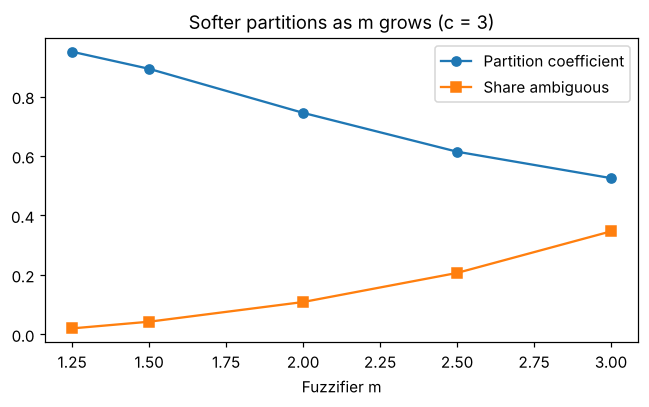

In [7]:
rows = []
for m in [1.25, 1.5, 2.0, 2.5, 3.0]:
    cntr, u_m, _, _, _, it, fpc = cmeans(pixels.T, c=3, m=m, error=0.005, maxiter=1000, seed=RANDOM_STATE)
    lab = match_labels(seg[3]['km'].labels_, u_m.argmax(axis=0), 3)
    rows.append({'m': m, 'FPC': fpc, 'Ambiguous pixels (max u < 0.6)': (u_m.max(axis=0) < 0.6).mean(),
                 'Agreement with K-Means': (lab == seg[3]['km'].labels_).mean(), 'Iterations': it})
m_tbl = pd.DataFrame(rows); display(m_tbl.round(4)); m_tbl.round(4).to_csv(MET_DIR / 'fuzzifier_effect.csv', index=False)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(m_tbl['m'], m_tbl['FPC'], 'o-', label='Partition coefficient'); ax.plot(m_tbl['m'], m_tbl['Ambiguous pixels (max u < 0.6)'], 's-', label='Share ambiguous')
ax.set_xlabel('Fuzzifier m'); ax.set_title('Softer partitions as m grows (c = 3)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'fuzzifier_effect.png', bbox_inches='tight'); plt.show()

**Observation:** The fuzzifier controls how many pixels are flagged as uncertain. At m = 1.25 the partition is almost crisp (partition coefficient 0.95, 2% ambiguous). At m = 3 it is very soft (0.53, 35% ambiguous). Hard-label agreement with K-Means stays above 98.6% throughout, so *m* changes the uncertainty map without changing the segmentation. m = 2, the conventional default, flags about one pixel in nine.

# Conclusion

| | c = 3 | c = 5 |
|---|---|---|
| Hard-label agreement, K-Means vs FCM | 99.25% | 97.7% |
| FCM partition coefficient (m = 2) | 0.745 | 0.657 |
| Ambiguous pixels (max membership < 0.6, m = 2) | 10.9% | - |

**Findings**
1. For segmentation alone, Fuzzy C-Means and K-Means give practically the same result on this image.
2. FCM's added value is the **uncertainty map**: about 11% of pixels are mixed, they lie on land-cover boundaries, and they are exactly where the two methods disagree.
3. The fuzzifier *m* sets how conservative that map is (2% to 35% ambiguous) without changing the hard segmentation.

**Limitations:** Clustering uses colour only, with no texture or spatial context, so shadows and dark vegetation share a class. There is no ground-truth land-cover map to measure accuracy. One small image.